In [19]:

# CELL 1 — Import libraries and upload the provided CSV

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("Please upload the instructor-provided CSV file.")

INPUT_FILE = csv_files[0]
df = pd.read_csv(INPUT_FILE)

print("Dataset loaded:", INPUT_FILE)
print("Shape (rows, columns):", df.shape)

display(df.head(10))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing Count"))

print("\nCategory frequencies:")
for col in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(20))


Saving Cleaned_Student_Service_Requests (1).csv to Cleaned_Student_Service_Requests (1).csv
Dataset loaded: Cleaned_Student_Service_Requests (1).csv
Shape (rows, columns): (400, 17)


,Request_ID,Service_Type,Requester_Type,Submission_Date,Requested_Channel,Priority,Assigned_Office,Queue_Length,Required_Documents_Complete,Processing_Days,SLA_Days,Status,Reopened,Satisfaction_Score,Submission_Weekday,Queue_Category,SLA_Breached
0,SR0001,Enrollment,Student,2025-03-15,Walk-in,Normal,Student Affairs,12.0,No,8.0,5.0,Completed,No,4.0,Saturday,Medium,1.0
1,SR0002,Enrollment,Student,2025-02-04,Portal,Normal,Student Affairs,8.0,Yes,4.0,5.0,Completed,No,5.0,Tuesday,Medium,0.0
2,SR0003,Enrollment,Student,2025-06-08,Portal,High,Student Affairs,5.0,Yes,6.0,3.0,Completed,No,3.0,Sunday,Low,1.0
3,SR0004,IT Support,Student,2025-10-21,Portal,Normal,IT Services,9.0,Yes,2.0,6.0,Completed,Yes,4.0,Tuesday,Medium,0.0
4,SR0005,Certification,Student,2025-12-30,Portal,Normal,Registrar,4.0,Yes,6.0,5.0,Completed,No,4.0,Tuesday,Low,1.0
5,SR0006,Scholarship Inquiry,Student,2025-08-31,Portal,Normal,Scholarship Office,11.0,Yes,NaN,6.0,Pending,No,NaN,Sunday,Medium,NaN
6,SR0007,Records,Student,2025-06-19,Portal,Low,Registrar,11.0,Yes,7.0,7.0,Completed,Yes,3.0,Thursday,Medium,0.0
7,SR0008,Records,Staff,2025-11-09,Portal,Normal,Registrar,7.0,No,5.0,5.0,Completed,No,3.0,Sunday,Medium,0.0
8,SR0009,IT Support,Student,2025-01-04,Portal,High,IT Services,8.0,No,4.0,4.0,Completed,No,5.0,Saturday,Medium,0.0
9,SR0010,Enrollment,Faculty,2025-11-24,Portal,High,Student Affairs,6.0,No,8.0,3.0,Completed,No,3.0,Monday,Medium,1.0



Column names:
['Request_ID', 'Service_Type', 'Requester_Type', 'Submission_Date', 'Requested_Channel', 'Priority', 'Assigned_Office', 'Queue_Length', 'Required_Documents_Complete', 'Processing_Days', 'SLA_Days', 'Status', 'Reopened', 'Satisfaction_Score', 'Submission_Weekday', 'Queue_Category', 'SLA_Breached']

Data types:


,Data Type
Request_ID,object
Service_Type,object
Requester_Type,object
Submission_Date,object
Requested_Channel,object
Priority,object
Assigned_Office,object
Queue_Length,float64
Required_Documents_Complete,object
Processing_Days,float64



Missing values:


,Missing Count
Request_ID,0
Service_Type,0
Requester_Type,0
Submission_Date,0
Requested_Channel,0
Priority,0
Assigned_Office,0
Queue_Length,0
Required_Documents_Complete,0
Processing_Days,73



Category frequencies:

--- Request_ID ---
Request_ID
SR0384    1
SR0383    1
SR0382    1
SR0381    1
SR0380    1
SR0379    1
SR0378    1
SR0377    1
SR0376    1
SR0375    1
SR0374    1
SR0373    1
SR0372    1
SR0371    1
SR0370    1
SR0369    1
SR0032    1
SR0031    1
SR0030    1
SR0029    1
Name: count, dtype: int64

--- Service_Type ---
Service_Type
Records                85
Certification          82
IT Support             69
Enrollment             66
Scholarship Inquiry    50
Finance                48
Name: count, dtype: int64

--- Requester_Type ---
Requester_Type
Student    319
Faculty     47
Staff       34
Name: count, dtype: int64

--- Submission_Date ---
Submission_Date
2025-07-20    5
2025-08-29    5
2025-06-19    4
2025-06-07    4
2025-04-05    4
2025-05-05    4
2025-03-30    4
2025-10-08    4
2025-01-10    4
2025-11-17    4
2025-01-26    4
2025-12-26    3
2025-03-04    3
2025-07-01    3
2025-01-25    3
2025-01-18    3
2025-07-10    3
2025-12-13    3
2025-12-30    3
2025-06-

In [26]:

# CELL 2 — Data quality, cleaning, and feature engineering

required_columns = [
    "Request_ID", "Service_Type", "Requester_Type",
    "Submission_Date", "Requested_Channel", "Priority",
    "Assigned_Office", "Queue_Length",
    "Required_Documents_Complete", "Processing_Days",
    "SLA_Days", "Status", "Reopened", "Satisfaction_Score"
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

clean = df.copy()
quality_log = []

def log_issue(issue, count, treatment):
    quality_log.append({
        "Issue": issue,
        "Records_Affected": int(count),
        "Treatment": treatment
    })

# 1. Duplicate identifiers
duplicate_count = clean["Request_ID"].duplicated(keep="first").sum()
log_issue(
    "Duplicate Request_ID",
    duplicate_count,
    "Kept the first occurrence and removed later duplicates."
)
clean = clean.drop_duplicates(subset=["Request_ID"], keep="first").copy()

# 2. Standardize text/category formatting
category_columns = [
    "Service_Type", "Requester_Type", "Requested_Channel",
    "Priority", "Assigned_Office",
    "Required_Documents_Complete", "Status", "Reopened"
]

for col in category_columns:
    before = clean[col].astype("string")
    after = before.str.strip().str.replace(r"\s+", " ", regex=True)
    changed = (before.fillna("<NA>") != after.fillna("<NA>")).sum()
    log_issue(
        f"Inconsistent formatting: {col}",
        changed,
        "Trimmed leading/trailing spaces and collapsed repeated spaces."
    )
    clean[col] = after

# Standardize case for the Yes/No and Status fields
for col in ["Required_Documents_Complete", "Status", "Reopened"]:
    clean[col] = clean[col].str.title()

# 3. Parse dates and record invalid non-missing values
original_dates = clean["Submission_Date"].copy()
parsed_dates = pd.to_datetime(original_dates, errors="coerce")
invalid_dates = (original_dates.notna() & parsed_dates.isna()).sum()

log_issue(
    "Invalid Submission_Date",
    invalid_dates,
    "Converted invalid dates to missing values; they are not used for weekday features."
)
clean["Submission_Date"] = parsed_dates

# 4. Convert numerical fields and identify negative values
numeric_columns = [
    "Queue_Length", "Processing_Days",
    "SLA_Days", "Satisfaction_Score"
]

for col in numeric_columns:
    original_nonmissing = clean[col].notna()
    clean[col] = pd.to_numeric(clean[col], errors="coerce")
    conversion_failures = (
        original_nonmissing & clean[col].isna()
    ).sum()

    log_issue(
        f"Non-numeric values: {col}",
        conversion_failures,
        "Converted unparseable values to missing."
    )

    negative_mask = clean[col] < 0
    negative_count = negative_mask.sum()
    log_issue(
        f"Negative values: {col}",
        negative_count,
        "Replaced negative values with missing values as invalid."
    )
    clean.loc[negative_mask, col] = np.nan

# 5. Report remaining missing values before imputation
for col in clean.columns:
    count = clean[col].isna().sum()
    if count:
        quality_log.append({
            "Issue": f"Missing values: {col}",
            "Records_Affected": int(count),
            "Treatment": (
                "Retained missingness; numerical/categorical predictors "
                "will be imputed within the model pipeline where appropriate. "
                "Rows without valid outcome labels are excluded from modeling."
            )
        })

# 6. Engineer requested features
clean["Submission_Weekday"] = clean["Submission_Date"].dt.day_name()

clean["Queue_Category"] = pd.cut(
    clean["Queue_Length"],
    bins=[-np.inf, 5, 15, np.inf],
    labels=["Low", "Medium", "High"]
)

# Create SLA_Breached only for completed records with known durations.
eligible = (
    clean["Status"].eq("Completed")
    & clean["Processing_Days"].notna()
    & clean["SLA_Days"].notna()
)

clean["SLA_Breached"] = pd.Series(
    pd.NA, index=clean.index, dtype="Int64"
)
clean.loc[eligible, "SLA_Breached"] = (
    clean.loc[eligible, "Processing_Days"]
    > clean.loc[eligible, "SLA_Days"]
).astype(int)

quality_log_df = pd.DataFrame(quality_log)

# Save outputs
BASE = "SectionB_Lastname_Firstname_ExamV2"
CLEANED_FILE = f"{BASE}.csv"
QUALITY_FILE = f"{BASE}_Data_Quality_Log.csv"

clean.to_csv(CLEANED_FILE, index=False)
quality_log_df.to_csv(QUALITY_FILE, index=False)

print("Cleaning complete.")
print("Original rows:", len(df))
print("Rows after duplicate-ID handling:", len(clean))
print("Eligible completed records with labels:", int(eligible.sum()))
print("\nQuality log:")
display(quality_log_df)

print("\nEngineered columns:")
display(clean[[
    "Request_ID", "Submission_Weekday",
    "Queue_Category", "Status", "SLA_Breached"
]].head(10))

print("\nSaved:", CLEANED_FILE, "and", QUALITY_FILE)


Cleaning complete.
Original rows: 400
Rows after duplicate-ID handling: 400
Eligible completed records with labels: 327

Quality log:


,Issue,Records_Affected,Treatment
0,Duplicate Request_ID,0,Kept the first occurrence and removed later du...
1,Inconsistent formatting: Service_Type,0,Trimmed leading/trailing spaces and collapsed ...
2,Inconsistent formatting: Requester_Type,0,Trimmed leading/trailing spaces and collapsed ...
3,Inconsistent formatting: Requested_Channel,0,Trimmed leading/trailing spaces and collapsed ...
4,Inconsistent formatting: Priority,0,Trimmed leading/trailing spaces and collapsed ...
5,Inconsistent formatting: Assigned_Office,0,Trimmed leading/trailing spaces and collapsed ...
6,Inconsistent formatting: Required_Documents_Co...,0,Trimmed leading/trailing spaces and collapsed ...
7,Inconsistent formatting: Status,0,Trimmed leading/trailing spaces and collapsed ...
8,Inconsistent formatting: Reopened,0,Trimmed leading/trailing spaces and collapsed ...
9,Invalid Submission_Date,0,Converted invalid dates to missing values; the...



Engineered columns:


,Request_ID,Submission_Weekday,Queue_Category,Status,SLA_Breached
0,SR0001,Saturday,Medium,Completed,1
1,SR0002,Tuesday,Medium,Completed,0
2,SR0003,Sunday,Low,Completed,1
3,SR0004,Tuesday,Medium,Completed,0
4,SR0005,Tuesday,Low,Completed,1
5,SR0006,Sunday,Medium,Pending,<NA>
6,SR0007,Thursday,Medium,Completed,0
7,SR0008,Sunday,Medium,Completed,0
8,SR0009,Saturday,Medium,Completed,0
9,SR0010,Monday,Medium,Completed,1



Saved: SectionB_Lastname_Firstname_ExamV2.csv and SectionB_Lastname_Firstname_ExamV2_Data_Quality_Log.csv


REQUEST VOLUME BY SERVICE TYPE


,Request_Count
Service_Type,
Records,85
Certification,82
IT Support,69
Enrollment,66
Scholarship Inquiry,50
Finance,48


Most frequent service type(s):


,count
Service_Type,
Records,85



SLA BREACH RATE BY OFFICE


,Completed_Eligible_Requests,Breaches,Breach_Rate,Breach_Rate_Percent
Assigned_Office,,,,
Scholarship Office,38,30,0.789474,78.947368
Finance Office,41,31,0.756098,75.609756
Student Affairs,57,33,0.578947,57.894737
Registrar,135,60,0.444444,44.444444
IT Services,56,13,0.232143,23.214286



SLA BREACH RATE BY QUEUE CATEGORY


,Eligible_Requests,Breaches,Breach_Rate,Breach_Rate_Percent
Queue_Category,,,,
Low,36,19,0.527778,52.777778
Medium,285,143,0.501754,50.175439
High,6,5,0.833333,83.333333


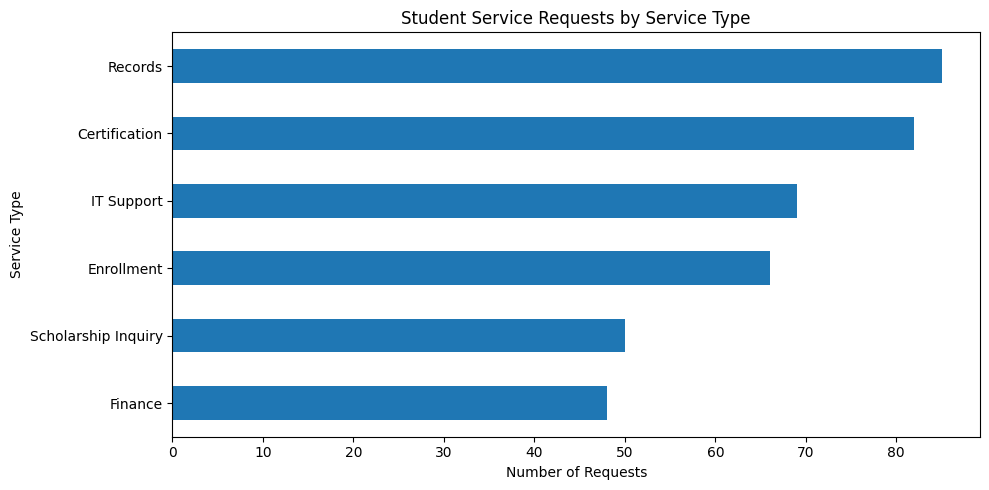

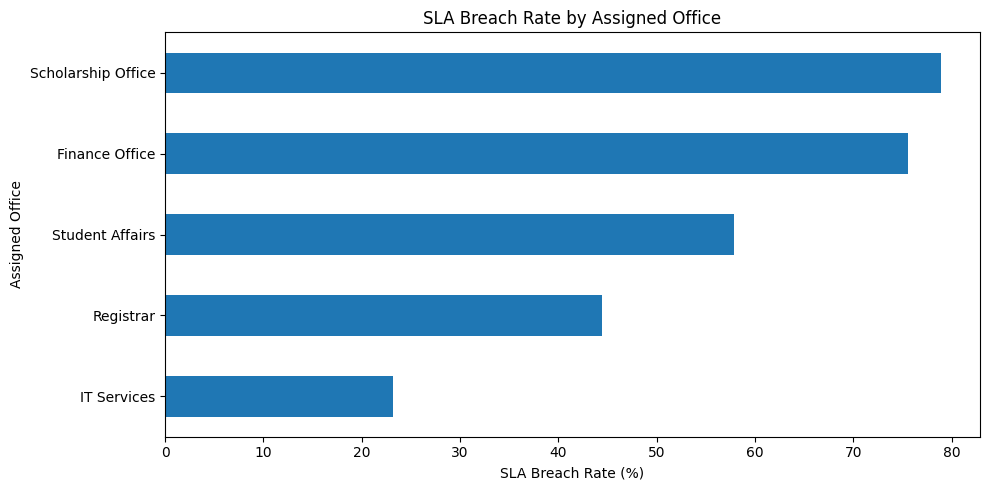

INTERPRETATION TASK
1. Describe the service type with the most requests, using the table above.
2. Identify the office with the highest breach rate and report its eligible request count.
3. Compare queue categories. Mention sample sizes and avoid treating small groups as conclusive.
4. Explain one practical management action supported by each chart.


In [21]:

# CELL 3 — Exploratory data analysis

print("REQUEST VOLUME BY SERVICE TYPE")
service_counts = clean["Service_Type"].value_counts(dropna=False)
display(service_counts.to_frame("Request_Count"))

if clean["Service_Type"].notna().any():
    print("Most frequent service type(s):")
    display(service_counts[service_counts == service_counts.max()])

# Use only eligible completed records for breach-rate calculations
labeled = clean.loc[clean["SLA_Breached"].notna()].copy()
labeled["SLA_Breached"] = labeled["SLA_Breached"].astype(int)

print("\nSLA BREACH RATE BY OFFICE")
office_stats = (
    labeled.groupby("Assigned_Office", dropna=False)
    .agg(
        Completed_Eligible_Requests=("SLA_Breached", "size"),
        Breaches=("SLA_Breached", "sum"),
        Breach_Rate=("SLA_Breached", "mean")
    )
    .sort_values("Breach_Rate", ascending=False)
)
office_stats["Breach_Rate_Percent"] = office_stats["Breach_Rate"] * 100
display(office_stats)

print("\nSLA BREACH RATE BY QUEUE CATEGORY")
queue_stats = (
    labeled.groupby("Queue_Category", observed=False, dropna=False)
    .agg(
        Eligible_Requests=("SLA_Breached", "size"),
        Breaches=("SLA_Breached", "sum"),
        Breach_Rate=("SLA_Breached", "mean")
    )
)
queue_stats["Breach_Rate_Percent"] = queue_stats["Breach_Rate"] * 100
display(queue_stats)

# Chart 1: Service volume
plt.figure(figsize=(10, 5))
service_counts.sort_values().plot(kind="barh")
plt.title("Student Service Requests by Service Type")
plt.xlabel("Number of Requests")
plt.ylabel("Service Type")
plt.tight_layout()
plt.savefig("SectionB_Chart1_Service_Volume.png", dpi=200)
plt.show()

# Chart 2: SLA breach rate by office
chart_office = office_stats["Breach_Rate_Percent"].dropna().sort_values()
plt.figure(figsize=(10, 5))
chart_office.plot(kind="barh")
plt.title("SLA Breach Rate by Assigned Office")
plt.xlabel("SLA Breach Rate (%)")
plt.ylabel("Assigned Office")
plt.tight_layout()
plt.savefig("SectionB_Chart2_SLA_Breach_Rate.png", dpi=200)
plt.show()

print("INTERPRETATION TASK")
print("1. Describe the service type with the most requests, using the table above.")
print("2. Identify the office with the highest breach rate and report its eligible request count.")
print("3. Compare queue categories. Mention sample sizes and avoid treating small groups as conclusive.")
print("4. Explain one practical management action supported by each chart.")


Predictor count: 10
Predictors: ['Service_Type', 'Requester_Type', 'Requested_Channel', 'Priority', 'Assigned_Office', 'Required_Documents_Complete', 'Submission_Weekday', 'Queue_Category', 'Queue_Length', 'SLA_Days']

Target class counts:


,Count
SLA_Breached,
0,160
1,167


Evaluation results:


,Model,Accuracy,Precision_Breach_Class,Recall_Breach_Class,F1_Breach_Class
0,Decision Tree,0.6515,0.6486,0.7059,0.6761
1,Majority-Class Baseline,0.5152,0.5152,1.0000,0.6800


Decision Tree confusion matrix
Rows = actual class [0, 1]; columns = predicted class [0, 1]


,Predicted: No Breach (0),Predicted: Breach (1)
Actual: No Breach (0),19,13
Actual: Breach (1),10,24



Classification report:
               precision    recall  f1-score   support

No SLA breach       0.66      0.59      0.62        32
   SLA breach       0.65      0.71      0.68        34

     accuracy                           0.65        66
    macro avg       0.65      0.65      0.65        66
 weighted avg       0.65      0.65      0.65        66

Top 10 influential encoded features:


,Feature,Importance
0,numeric__Queue_Length,0.209766
1,numeric__SLA_Days,0.140020
7,categorical__Service_Type_Scholarship Inquiry,0.072667
24,categorical__Submission_Weekday_Friday,0.063469
22,categorical__Required_Documents_Complete_No,0.056998
16,categorical__Priority_Normal,0.049298
12,categorical__Requested_Channel_Portal,0.048423
28,categorical__Submission_Weekday_Thursday,0.042161
30,categorical__Submission_Weekday_Wednesday,0.041508
29,categorical__Submission_Weekday_Tuesday,0.040683


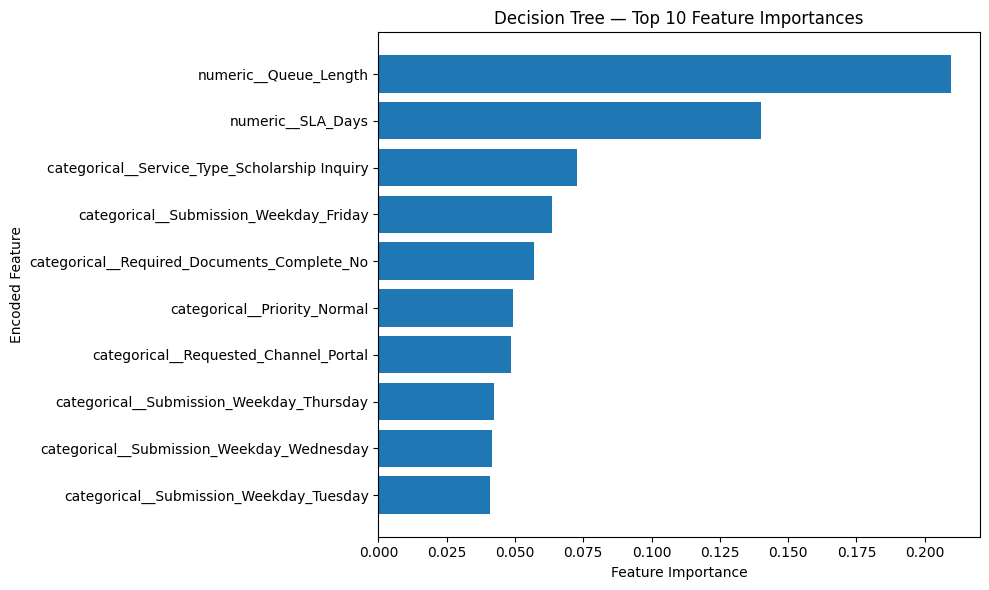


Interpretation tasks:
- Compare Decision Tree performance with the majority-class baseline.
- Explain what precision and recall mean for identifying SLA breaches.
- Identify the top three influential features from the table.
- Discuss one data leakage risk and one class-imbalance risk.
- Explain why the model should support human review, not make final decisions.


In [22]:

# CELL 4 — Decision Tree classification and evaluation

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

# Only rows with a valid, eligible target may be used for modeling
model_df = clean.loc[clean["SLA_Breached"].notna()].copy()
model_df["SLA_Breached"] = model_df["SLA_Breached"].astype(int)

# Submission-time predictors only
categorical_features = [
    "Service_Type",
    "Requester_Type",
    "Requested_Channel",
    "Priority",
    "Assigned_Office",
    "Required_Documents_Complete",
    "Submission_Weekday",
    "Queue_Category"
]

numerical_features = ["Queue_Length", "SLA_Days"]
features = categorical_features + numerical_features
target = "SLA_Breached"

# Drop predictors that are unavailable or entirely empty in this dataset
features = [c for c in features if c in model_df.columns]
categorical_features = [c for c in categorical_features if c in features]
numerical_features = [c for c in numerical_features if c in features]

X = model_df[features].copy()
y = model_df[target].astype(int)

print("Predictor count:", len(features))
print("Predictors:", features)
print("\nTarget class counts:")
display(y.value_counts().sort_index().to_frame("Count"))

if len(features) < 5:
    raise ValueError(
        "Fewer than five usable predictors were found. "
        "Check the dataset schema and adapt the predictor list."
    )

if y.nunique() < 2 or y.value_counts().min() < 2:
    raise ValueError(
        "The target needs both classes and at least two examples per class "
        "for this train/test procedure."
    )

# 80/20 split; fixed seed for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight=None
    ))
])

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

tree_model.fit(X_train, y_train)
baseline_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)
baseline_predictions = baseline_model.predict(X_test)

def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision_Breach_Class": precision_score(
            actual, predicted, pos_label=1, zero_division=0
        ),
        "Recall_Breach_Class": recall_score(
            actual, predicted, pos_label=1, zero_division=0
        ),
        "F1_Breach_Class": f1_score(
            actual, predicted, pos_label=1, zero_division=0
        )
    }

evaluation = pd.DataFrame([
    evaluate_model("Decision Tree", y_test, tree_predictions),
    evaluate_model("Majority-Class Baseline", y_test, baseline_predictions)
])

print("Evaluation results:")
display(evaluation.round(4))

print("Decision Tree confusion matrix")
print("Rows = actual class [0, 1]; columns = predicted class [0, 1]")
cm = confusion_matrix(y_test, tree_predictions, labels=[0, 1])
display(pd.DataFrame(
    cm,
    index=["Actual: No Breach (0)", "Actual: Breach (1)"],
    columns=["Predicted: No Breach (0)", "Predicted: Breach (1)"]
))

print("\nClassification report:")
print(classification_report(
    y_test, tree_predictions,
    labels=[0, 1],
    target_names=["No SLA breach", "SLA breach"],
    zero_division=0
))

# Extract transformed feature names and importance scores
fitted_preprocessor = tree_model.named_steps["preprocessor"]
transformed_names = fitted_preprocessor.get_feature_names_out()
importances = tree_model.named_steps["classifier"].feature_importances_

feature_importance = (
    pd.DataFrame({
        "Feature": transformed_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
)

print("Top 10 influential encoded features:")
display(feature_importance.head(10))

evaluation.to_csv("SectionB_Model_Evaluation.csv", index=False)
feature_importance.to_csv("SectionB_Feature_Importance.csv", index=False)

# Chart of feature importance
top_features = feature_importance.head(10).sort_values("Importance")
plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Decision Tree — Top 10 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Encoded Feature")
plt.tight_layout()
plt.savefig("SectionB_Feature_Importance.png", dpi=200)
plt.show()

print("\nInterpretation tasks:")
print("- Compare Decision Tree performance with the majority-class baseline.")
print("- Explain what precision and recall mean for identifying SLA breaches.")
print("- Identify the top three influential features from the table.")
print("- Discuss one data leakage risk and one class-imbalance risk.")
print("- Explain why the model should support human review, not make final decisions.")


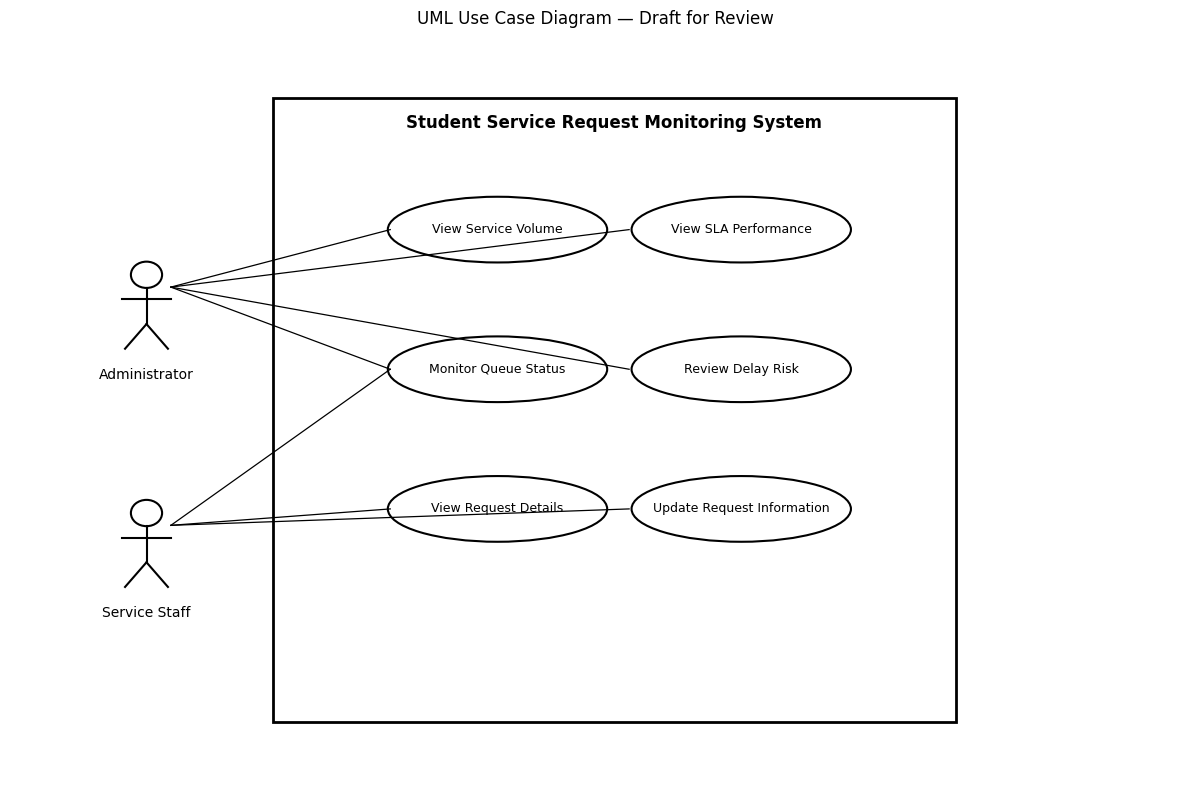

Diagram saved as SectionB_Lastname_Firstname_ExamV2_UML.png
Review the actor associations and adapt them to your actual requirements.


In [23]:

# CELL 5 — Basic UML use case diagram (PNG)

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle, Circle

fig, ax = plt.subplots(figsize=(12, 8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 9)
ax.axis("off")

# System boundary
ax.add_patch(Rectangle((2.7, 0.7), 7.0, 7.6, fill=False, linewidth=2))
ax.text(6.2, 8.0, "Student Service Request Monitoring System",
        ha="center", va="center", fontsize=12, weight="bold")

# Actors
def draw_actor(x, y, label):
    ax.add_patch(Circle((x, y + 0.65), 0.16, fill=False, linewidth=1.5))
    ax.plot([x, x], [y + 0.49, y + 0.05], color="black")
    ax.plot([x - 0.25, x + 0.25], [y + 0.35, y + 0.35], color="black")
    ax.plot([x, x - 0.22], [y + 0.05, y - 0.25], color="black")
    ax.plot([x, x + 0.22], [y + 0.05, y - 0.25], color="black")
    ax.text(x, y - 0.48, label, ha="center", va="top", fontsize=10)

draw_actor(1.4, 5.5, "Administrator")
draw_actor(1.4, 2.6, "Service Staff")

# Use cases
use_cases = [
    (5.0, 6.7, "View Service Volume"),
    (7.5, 6.7, "View SLA Performance"),
    (5.0, 5.0, "Monitor Queue Status"),
    (7.5, 5.0, "Review Delay Risk"),
    (5.0, 3.3, "View Request Details"),
    (7.5, 3.3, "Update Request Information"),
]

for x, y, label in use_cases:
    ax.add_patch(Ellipse((x, y), 2.25, 0.8, fill=False, linewidth=1.5))
    ax.text(x, y, label, ha="center", va="center", fontsize=9)

# Actor associations (solid lines)
admin_links = [
    (1.65, 6.0, 3.9, 6.7),
    (1.65, 6.0, 6.35, 6.7),
    (1.65, 6.0, 3.9, 5.0),
    (1.65, 6.0, 6.35, 5.0),
]
staff_links = [
    (1.65, 3.1, 3.9, 3.3),
    (1.65, 3.1, 6.35, 3.3),
    (1.65, 3.1, 3.9, 5.0),
]

for x1, y1, x2, y2 in admin_links + staff_links:
    ax.plot([x1, x2], [y1, y2], color="black", linewidth=0.9)

plt.title("UML Use Case Diagram — Draft for Review", pad=12)
plt.tight_layout()
plt.savefig("SectionB_Lastname_Firstname_ExamV2_UML.png",
            dpi=220, bbox_inches="tight")
plt.show()

print("Diagram saved as SectionB_Lastname_Firstname_ExamV2_UML.png")
print("Review the actor associations and adapt them to your actual requirements.")


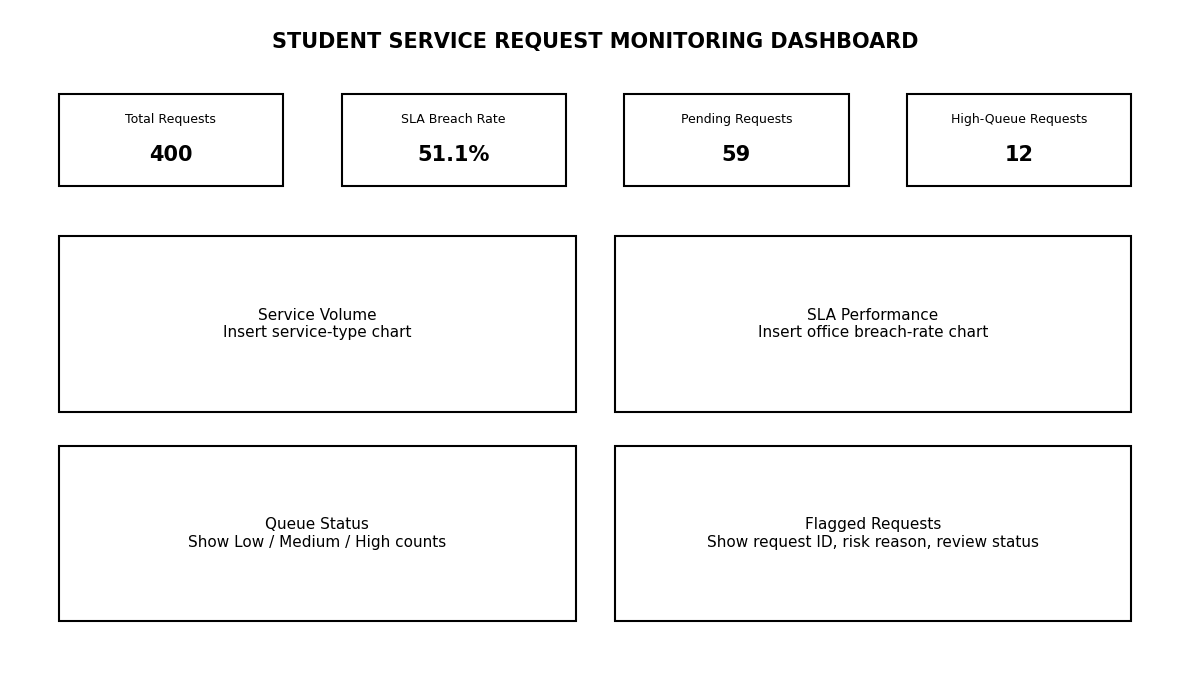

Dashboard wireframe saved.
Use actual results and protect student information in any real dashboard.


In [24]:

# CELL 6 — Administrator dashboard wireframe

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

ax.text(6, 7.55, "STUDENT SERVICE REQUEST MONITORING DASHBOARD",
        ha="center", fontsize=15, weight="bold")

# Summary cards based on the loaded data
total_requests = len(clean)
breach_rate = (
    labeled["SLA_Breached"].mean() * 100 if len(labeled) else np.nan
)
pending_count = clean["Status"].eq("Pending").sum()
high_queue_count = clean["Queue_Category"].eq("High").sum()

cards = [
    (0.5, "Total Requests", f"{total_requests}"),
    (3.4, "SLA Breach Rate", f"{breach_rate:.1f}%" if pd.notna(breach_rate) else "N/A"),
    (6.3, "Pending Requests", f"{pending_count}"),
    (9.2, "High-Queue Requests", f"{high_queue_count}")
]

for x, label, value in cards:
    ax.add_patch(Rectangle((x, 5.9), 2.3, 1.1, fill=False, linewidth=1.5))
    ax.text(x + 1.15, 6.65, label, ha="center", fontsize=9)
    ax.text(x + 1.15, 6.2, value, ha="center", fontsize=15, weight="bold")

# Panel placeholders
panels = [
    (0.5, 3.2, 5.3, 2.1, "Service Volume\nInsert service-type chart"),
    (6.2, 3.2, 5.3, 2.1, "SLA Performance\nInsert office breach-rate chart"),
    (0.5, 0.7, 5.3, 2.1, "Queue Status\nShow Low / Medium / High counts"),
    (6.2, 0.7, 5.3, 2.1, "Flagged Requests\nShow request ID, risk reason, review status")
]

for x, y, w, h, label in panels:
    ax.add_patch(Rectangle((x, y), w, h, fill=False, linewidth=1.5))
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", fontsize=11)

plt.tight_layout()
plt.savefig("SectionB_Dashboard_Wireframe.png", dpi=200, bbox_inches="tight")
plt.show()

print("Dashboard wireframe saved.")
print("Use actual results and protect student information in any real dashboard.")


In [25]:
print("=== OFFICE STATS FOR REPORT ===")
display(office_stats[['Completed_Eligible_Requests', 'Breaches', 'Breach_Rate_Percent']].round(2))

print("\n=== QUEUE STATS FOR REPORT ===")
display(queue_stats[['Eligible_Requests', 'Breaches', 'Breach_Rate_Percent']].round(2))

=== OFFICE STATS FOR REPORT ===


,Completed_Eligible_Requests,Breaches,Breach_Rate_Percent
Assigned_Office,,,
Scholarship Office,38,30,78.95
Finance Office,41,31,75.61
Student Affairs,57,33,57.89
Registrar,135,60,44.44
IT Services,56,13,23.21



=== QUEUE STATS FOR REPORT ===


,Eligible_Requests,Breaches,Breach_Rate_Percent
Queue_Category,,,
Low,36,19,52.78
Medium,285,143,50.18
High,6,5,83.33
